## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import flask
import sklearn
import sys

# Version 

In [2]:
print(f"Python version: {sys.version.split()[0]}")
print(f"Flask version: {flask.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")

Python version: 3.10.20
Flask version: 3.1.3
Scikit-learn version: 1.7.2
Pandas version: 2.3.3
Numpy version: 2.2.5


C:\Users\User\AppData\Local\Temp\ipykernel_12344\3582156191.py:2: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print(f"Flask version: {flask.__version__}")


## Import Data 

In [3]:
df=pd.read_csv("../data/bengaluru_house_prices.csv")
df.head()


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
# Basic infor about data
print("The Shape of Data :",df.shape)


print("The Rows of data :",df.shape[0])

print("the columns of data :",df.shape[1])

The Shape of Data : (13320, 9)
The Rows of data : 13320
the columns of data : 9


##  Basic Inof About data 


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


## Basic Asseasing

In [6]:
df.drop_duplicates(inplace=True)

- In this dataset there are many Duplicated and  missing values are present

## Remove Columns 

In [7]:
df2=df.drop(['availability','society'],axis=1)

In [8]:
# Getting Average of SQRT 
def convert_sqrt(x):
    token= x.split('-')
    if len(token)==2:
        return ( float(token[0].strip())+float(token[1].strip())/2)
    try:
        return float(x)
    except:
        return None

In [9]:
df2['total_sqft']=df2['total_sqft'].apply(convert_sqrt)

In [10]:
df2['location'].fillna(df2['location'].mode()[0],inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12344\1407278169.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['location'].fillna(df2['location'].mode()[0],inplace=True)


-  converting the range of area into average of range

In [11]:
# Set a threshold (10 is safe; 20 is safer to avoid overfitting)
threshold = 10
location_counts=df2['location'].value_counts()

df2['location_processed'] = df2['location'].apply(lambda x : x if location_counts[x] >= threshold else 'Other')
print(df2['location_processed'].nunique())


250


In [12]:
df2.columns

Index(['area_type', 'location', 'size', 'total_sqft', 'bath', 'balcony',
       'price', 'location_processed'],
      dtype='object')

## EDA
###  Univariate analysis

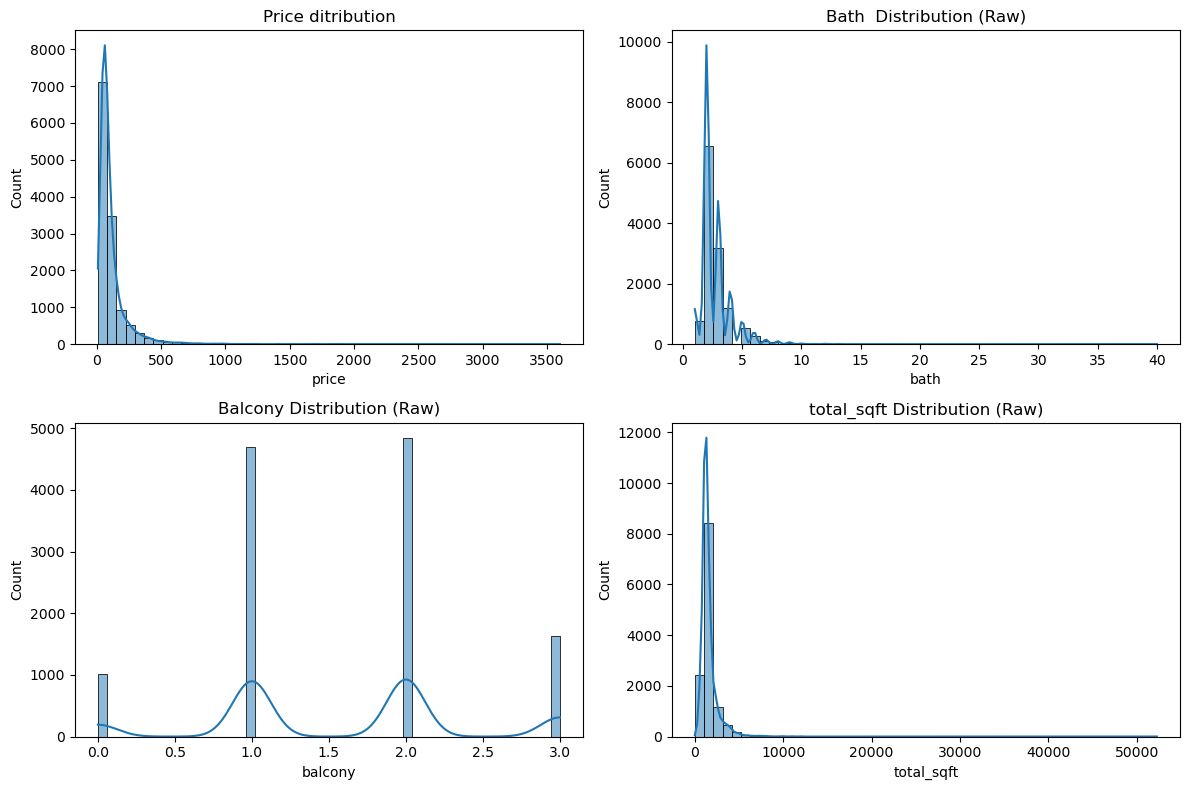

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# Price
sns.histplot(df2['price'], bins=50, kde=True, ax=axes[0,0])
axes[0,0].set_title("Price ditribution")
sns.histplot(df2['bath'], bins=50, kde=True, ax=axes[0,1])
axes[0,1].set_title('Bath  Distribution (Raw)')
sns.histplot(df2['balcony'], bins=50, kde=True, ax=axes[1,0])
axes[1,0].set_title('Balcony Distribution (Raw)')
sns.histplot(df2['total_sqft'], bins=50, kde=True, ax=axes[1,1])
axes[1,1].set_title('total_sqft Distribution (Raw)')
plt.tight_layout()
plt.show()


**In conclusion**
- *Price*: It has extrime out liers and it is right skewed data.
- *Bath*: the Bath data also right skewed.
- *Balcony*: the column shows dicrete ditribution,the more house has 2 and 3 calonies
- *total_sqft*: this columsn also have extrime outliers, we have perform preprocessing on it also

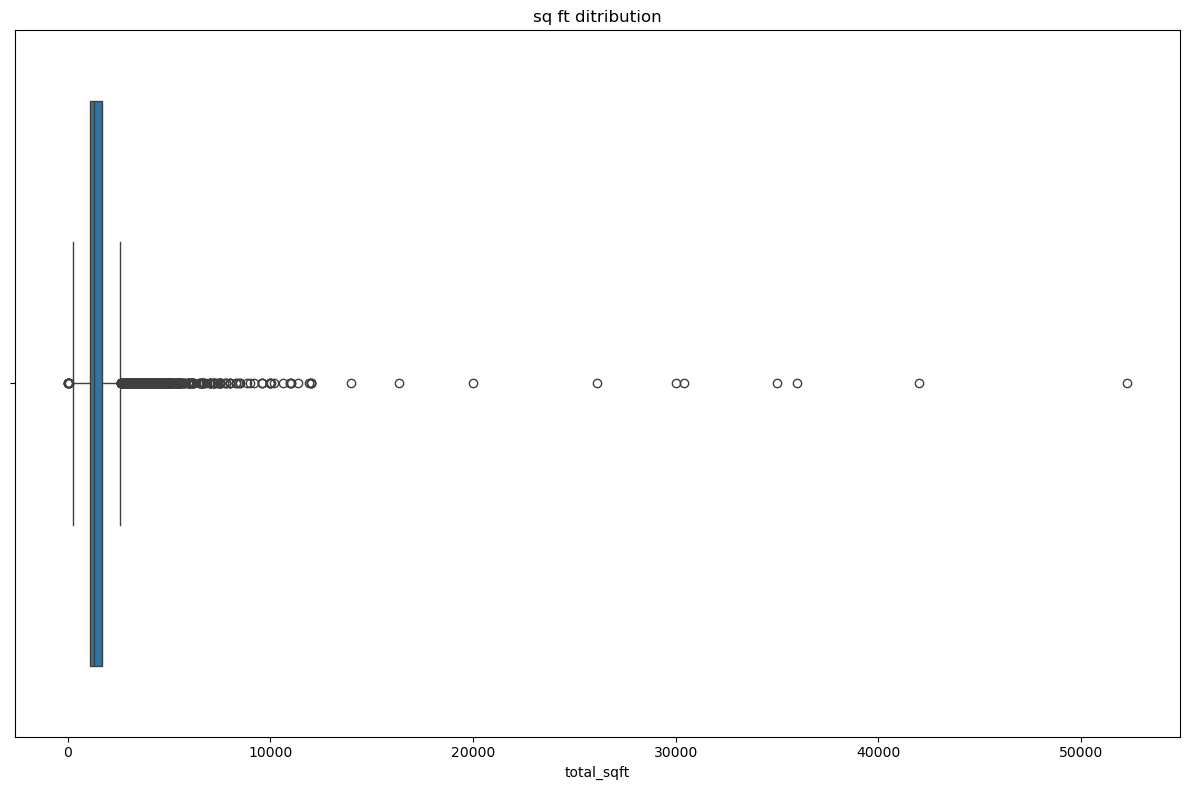

In [14]:
plt.figure(figsize=(12, 8))
# Price
sns.boxplot(x=df2['total_sqft'])
plt.title("sq ft ditribution")
plt.tight_layout()
plt.show()

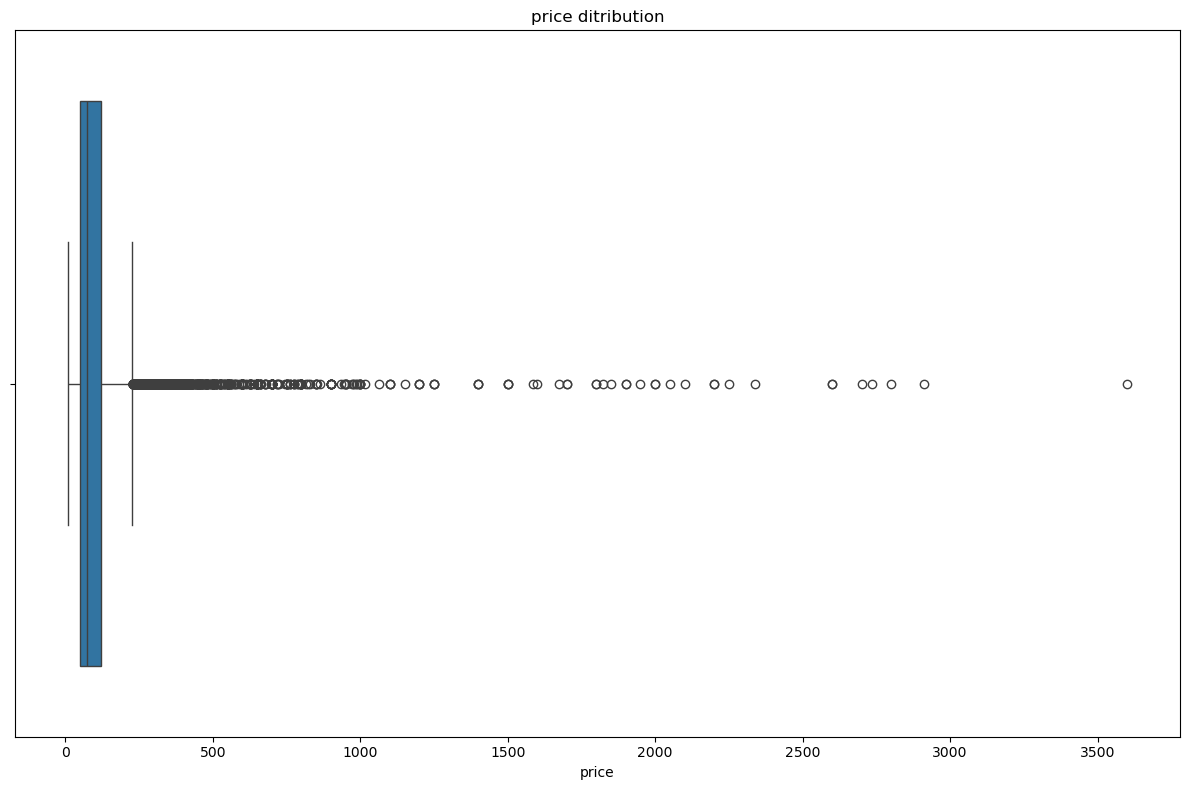

In [15]:
plt.figure(figsize=(12, 8))
# Price
sns.boxplot(x=df2['price'])
plt.title("price ditribution")
plt.tight_layout()
plt.show()

In [16]:
df2['location_processed'].value_counts()
print("Most ten frequent location",df2['location_processed'].head(10))
print("Least frequent location",df2['location_processed'].tail(10))

Most ten frequent location 0    Electronic City Phase II
1            Chikka Tirupathi
2                 Uttarahalli
3          Lingadheeranahalli
4                    Kothanur
5                  Whitefield
6            Old Airport Road
7                Rajaji Nagar
8                Marathahalli
9                       Other
Name: location_processed, dtype: object
Least frequent location 13307             Billekahalli
13308        Bannerghatta Road
13309             Yeshwanthpur
13310             Rachenahalli
13312                Bellandur
13314        Green Glen Layout
13315               Whitefield
13316                    Other
13317    Raja Rajeshwari Nagar
13318          Padmanabhanagar
Name: location_processed, dtype: object


**Location**: In this  data set we have 250 unique locations

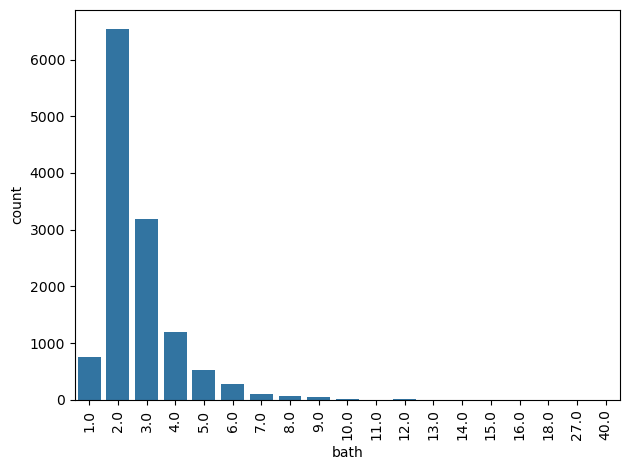

In [17]:
sns.countplot(data=df2, x="bath")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- in this data there is more  bath rooms in between 1 to  6 and few bath rooms in between 7 to 10 and from 10 to 40 there are few bath rooms

In [18]:
df2['bhk']=df2['size'].str.split().str[0]

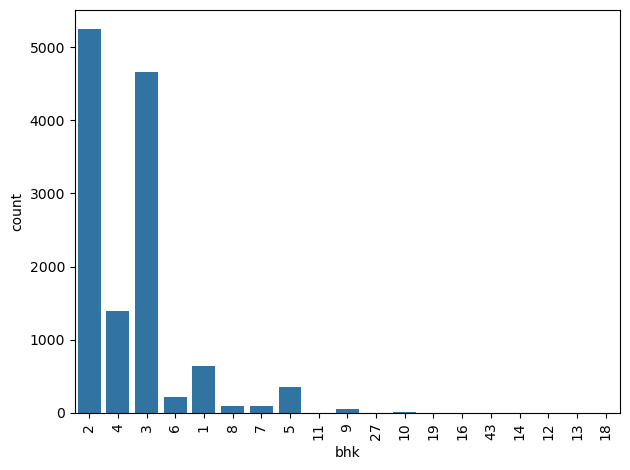

In [19]:
sns.countplot(data=df2, x="bhk")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- In this data there is more 2 BHK rooms , 3 bhk rooms ,other BHK  rooms are few

***Feature Engineering***

***getting a new feature bhk***

In [20]:
df2=df2.drop(columns=['area_type','location'])

In [21]:
# changing data types
df2['bhk']=df2['bhk'].astype('float')
df2['total_sqft']=df2['total_sqft'].astype('float')

In [22]:
df2['price_per_sqrt']=df2['price']*100000/df2['total_sqft']

In [23]:
# selecting those columns that  have more then 300 sqare foot area per bhk
df2=df2[df2['total_sqft']/df2['bhk']>300]

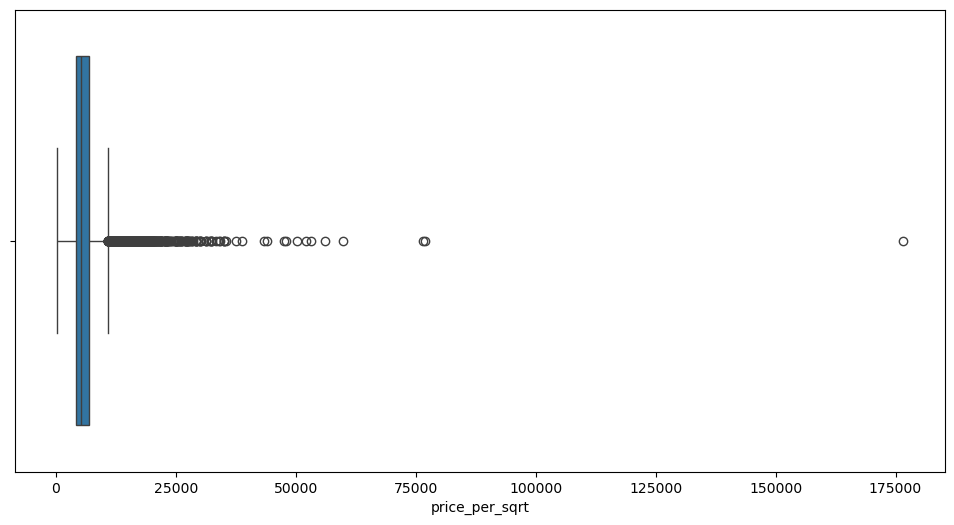

In [24]:
plt.figure(figsize=(12,6))
sns.boxplot(x=df2['price_per_sqrt'])
plt.show()

## Bivariavte analysis

In [25]:
df2['price_per_sqrt'].describe()

count     11813.000000
mean       6240.795912
std        4118.526922
min         267.829813
25%        4198.473282
50%        5281.690141
75%        6859.504132
max      176470.588235
Name: price_per_sqrt, dtype: float64

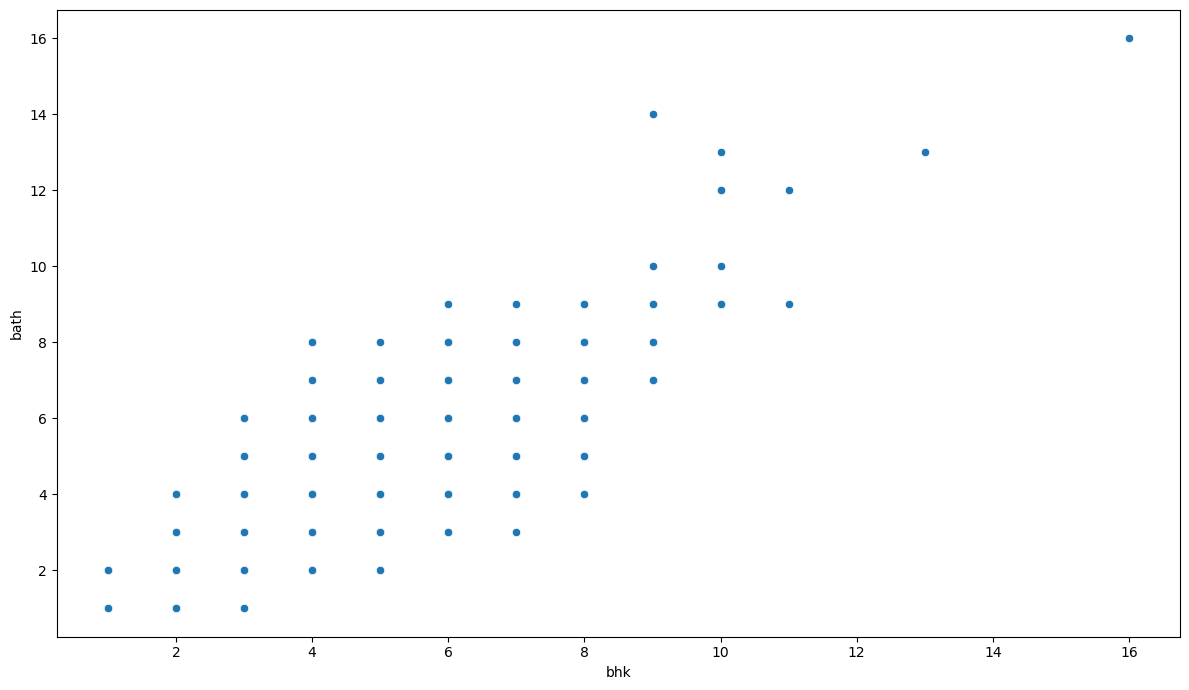

In [26]:
## EDA  
# Bhk vs bath
plt.figure(figsize=(12, 7))
sns.scatterplot(x=df2['bhk'],y=df2['bath'])
plt.tight_layout()
plt.show()

*BHK vs Bath*
- has positive relaiton as bhk increase bath also increases.

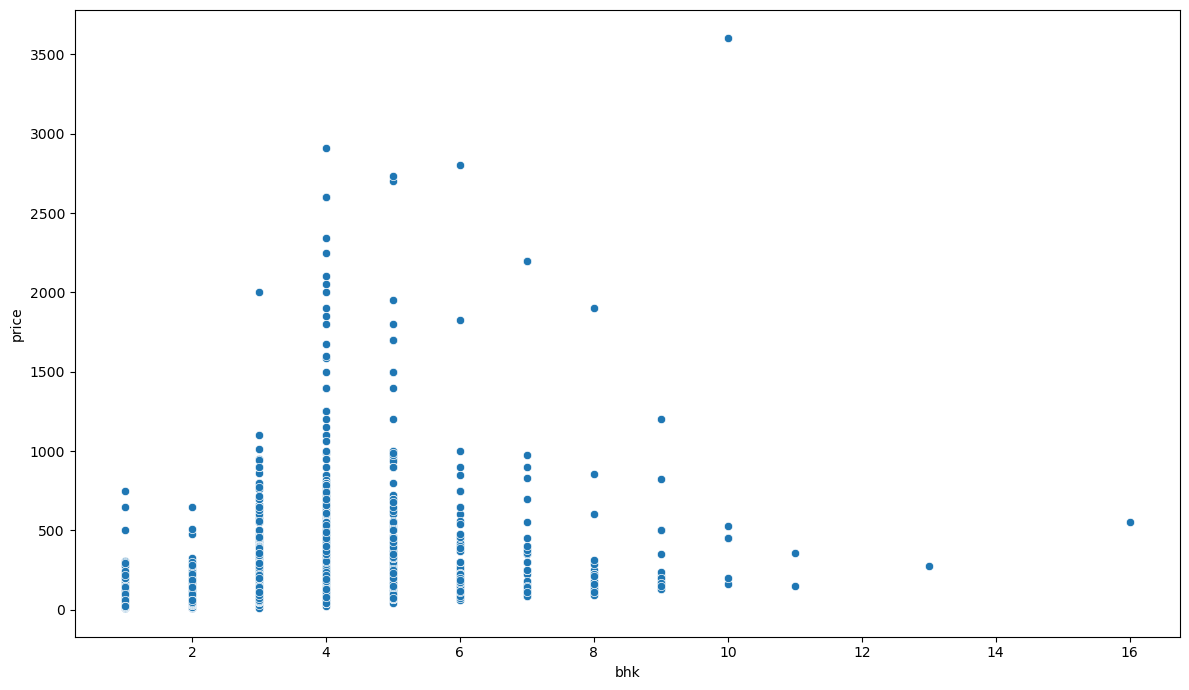

In [27]:
plt.figure(figsize=(12, 7))
sns.scatterplot(x=df2['bhk'],y=df2['price'])
plt.tight_layout()
plt.show()

*price vs bhk*
- show positvie relation.
- many house wiht different price has same price
- some higher bhk houses has small price , this may be due to location , area or condition od house

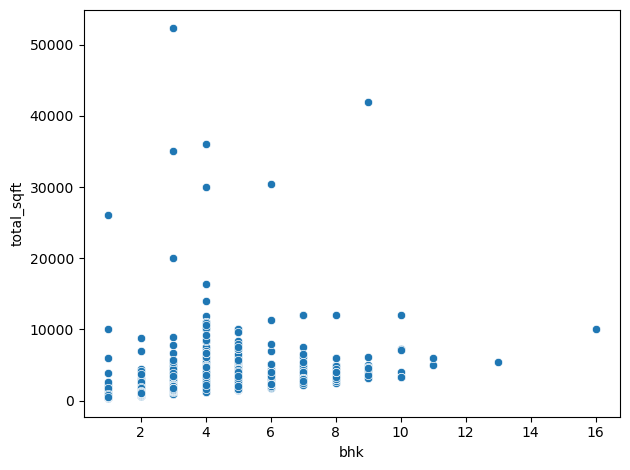

In [28]:
sns.scatterplot(x=df2['bhk'],y=df2['total_sqft'])
plt.tight_layout()
plt.show()

**total_sqft vs bhk**
- as bhk increases sq ft also increases.
- but there is also some house wiht same sq ft has different bhk.

**General rule**: Bigger size usually means more bedrooms.The surprise: Two homes with the same total size can have different room counts.Example: A huge 4-bedroom house and a crowded 10-bedroom house can take up the exact same amount of space.

Text(0.5, 1.0, 'BHK vs total_sqft')

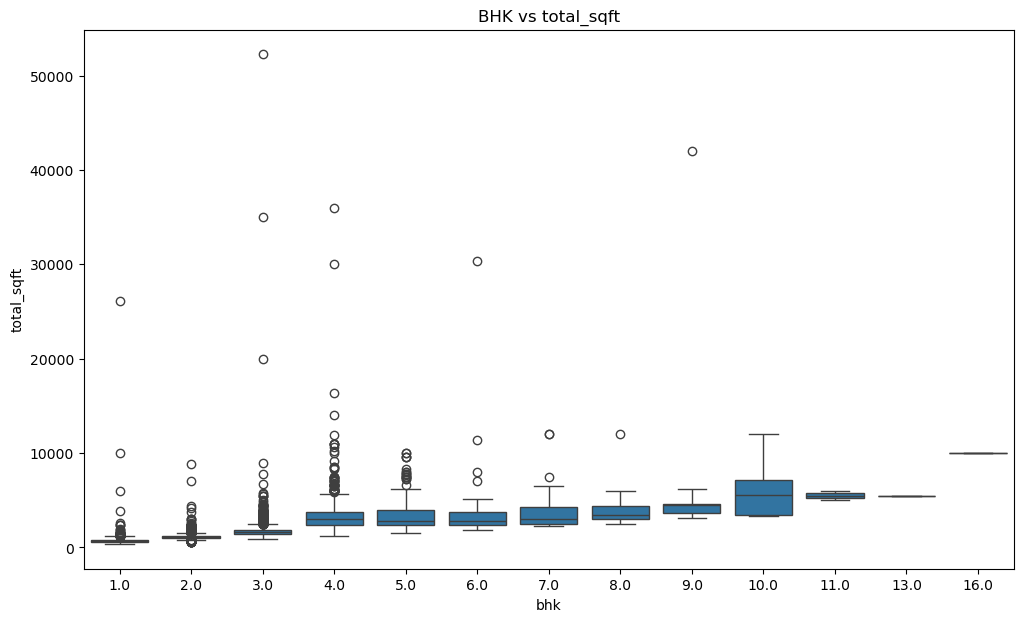

In [29]:
plt.figure(figsize=(12,7))
sns.boxplot(data=df2,x='bhk',y='total_sqft')
plt.title("BHK vs total_sqft")

**Visual Analysis: bhk vs total_sqft**
- Extreme Outliers: There are severe outliers in total square footage across the 1.0 to 9.0 BHK categories. To avoid model distortion during training, we must apply preprocessing filters—such as capping or removing rows where total_sqft exceeds 13,000 sq ft, or filtering outliers relative to each BHK group using statistical methods (like IQR).

- Data Sparsity: Properties with 11.0 to 16.0 BHK suffer from severe data sparsity (too few rows to establish a normal distribution). Before modeling, these rare categories should either be filtered out or grouped into a broader bucket (e.g., "8+ BHK").

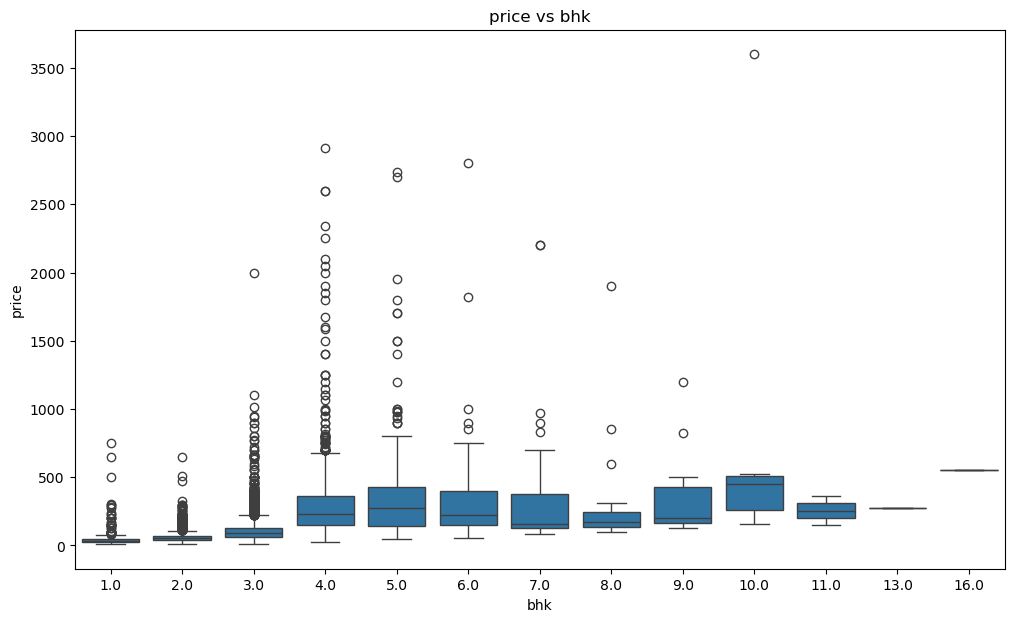

In [30]:
plt.figure(figsize=(12,7))
sns.boxplot(data=df2,x='bhk',y='price')
plt.title("price vs bhk")
plt.show()

**price vs bhk**
- based on bhk there are many outliers in our data
- same bhk has different prices, like 1 bhk has price from 3lac to 7lac 
- and also  different bhk has differen prices may be due location houe condition etc.
- so based on just bhk we did not make any transformation


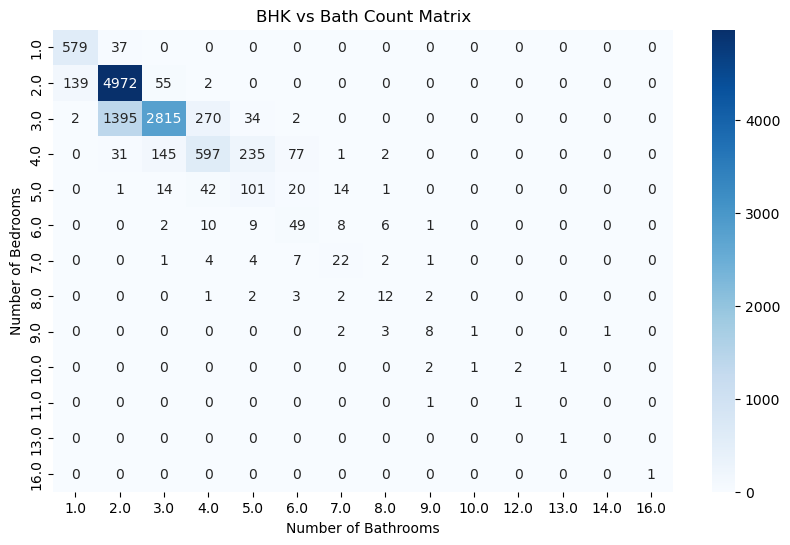

In [31]:
ct = pd.crosstab(df2['bhk'], df2['bath'])
# 2. Plot as a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('BHK vs Bath Count Matrix')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Number of Bedrooms')
plt.show()

**bhk vs bath**
- In this data some bhk has more bathrooms  then ad rooms, so we remove these rows how has many bath rooms like 9bhk has 14 bath rooms. whihc like a mistake.

In [32]:
location_median = df2.groupby('location_processed')['price_per_sqrt'].median().sort_values(ascending=False)
expensive_10 = location_median.head(10)
cheapest_10 = location_median.tail(10)


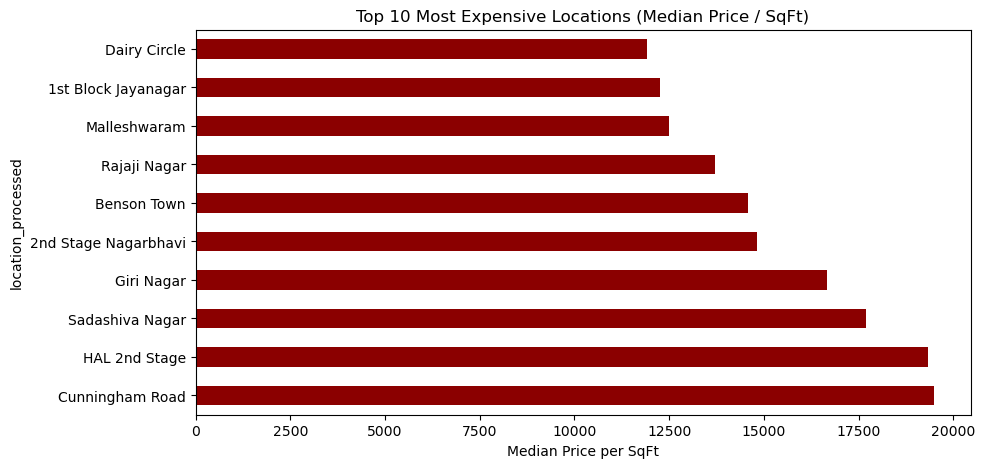

In [33]:
plt.figure(figsize=(10, 5))
expensive_10.plot(kind='barh', color='darkred')
plt.title('Top 10 Most Expensive Locations (Median Price / SqFt)')
plt.xlabel('Median Price per SqFt')
plt.show()

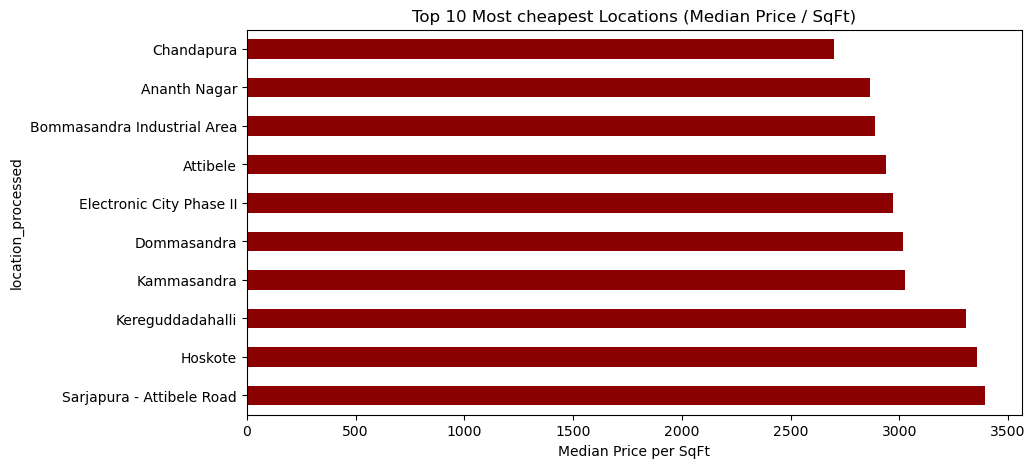

In [34]:
plt.figure(figsize=(10, 5))
cheapest_10.tail(10).plot(kind='barh', color='darkred')
plt.title('Top 10 Most cheapest Locations (Median Price / SqFt)')
plt.xlabel('Median Price per SqFt')
plt.show()

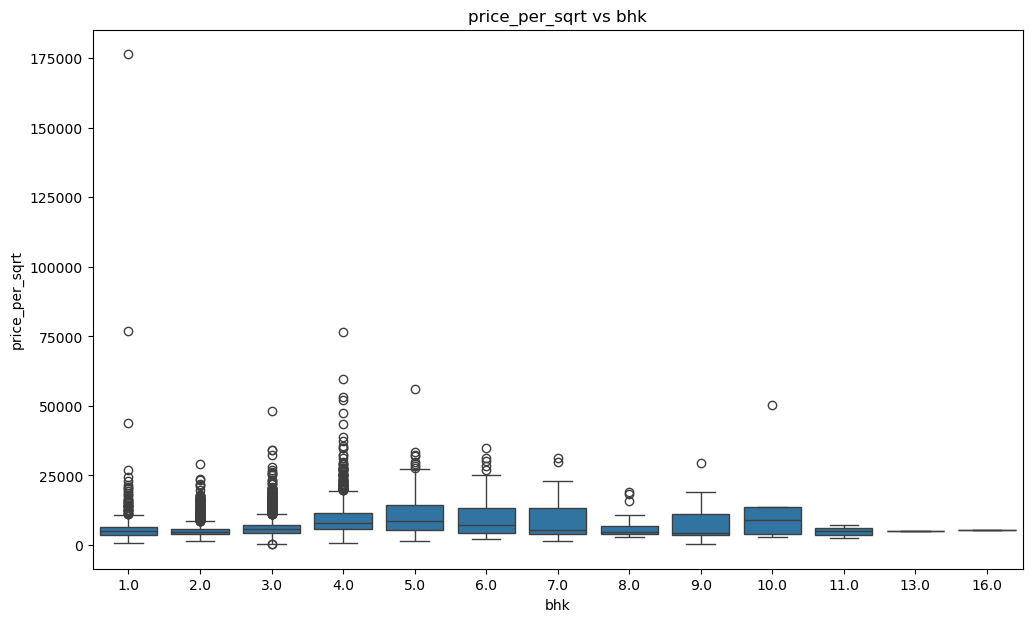

In [35]:
plt.figure(figsize=(12,7))
sns.boxplot(data=df2,x='bhk',y='price_per_sqrt')
plt.title("price_per_sqrt vs bhk")
plt.show()

## Preprocessing

In [36]:
# remove number of baths that are unreal

def remove_bath(df):
    df_out = pd.DataFrame()
    for bhk,subdf in df.groupby('bhk'):
        subdf =subdf[(subdf.bath<=subdf.bhk+2)]
        df_out =pd.concat([df_out,subdf],ignore_index=True)
    return df_out

def remove_sqft_price_outlier_iqr_loc(df):
    out_df=pd.DataFrame()
    for location,subdf in df.groupby('location_processed'):
        q1=subdf['price_per_sqrt'].quantile(0.25)
        q3=subdf['price_per_sqrt'].quantile(0.75)
        iqr=q3-q1
        lower=q1-1.5*iqr
        upper=q3+1.5*iqr
        subdf=subdf[(subdf.price_per_sqrt>lower)&(subdf.price_per_sqrt<upper)]
        out_df=pd.concat([out_df,subdf],ignore_index=True)
    return out_df

def remove_sqft_price_outlier_iqr_bhk(df):
    out_df=pd.DataFrame()
    for location,subdf in df.groupby('bhk'):
        q1=subdf['price_per_sqrt'].quantile(0.25)
        q3=subdf['price_per_sqrt'].quantile(0.75)
        iqr=q3-q1
        lower=q1-1.5*iqr
        upper=q3+1.5*iqr
        subdf=subdf[(subdf.price_per_sqrt>=lower)&(subdf.price_per_sqrt<=upper)]
        out_df=pd.concat([out_df,subdf],ignore_index=True)
    return out_df

def remove_outlier_bhk(df):
    ex_idx=np.array([])
    
    for location , subdf in df.groupby('location_processed'):
        bhk_stats={}

        for bhk , bhk_df in subdf.groupby('bhk'):
            bhk_stats[bhk]={
             'mean':bhk_df['price_per_sqrt'].mean(),
             'count':bhk_df.shape[0]
            }
        for bhk , bhk_df in subdf.groupby('bhk'):
            stat=bhk_stats.get(bhk-1)
            if stat and stat['count']>5:
                ex_idx = np.append(ex_idx,bhk_df[bhk_df['price_per_sqrt']<(stat['mean'])].index.values)
    return df.drop(ex_idx,axis='index')


In [37]:
## remove hgih bhk that create sparsity
df2['bhk']=df2['bhk'].apply(lambda x : x if x<10 else 9)
df2=remove_bath(df2)
df2=remove_sqft_price_outlier_iqr_bhk(df2)
df2=remove_sqft_price_outlier_iqr_loc(df2)
df2=remove_outlier_bhk(df2)

In [38]:
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_predict,cross_val_score,ShuffleSplit
from sklearn.linear_model import LinearRegression,LogisticRegression,Lasso,Ridge
from sklearn.svm import SVR
from sklearn.tree  import DecisionTreeRegressor
from sklearn.ensemble import VotingRegressor,BaggingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor


In [39]:
final_df=df2.drop(columns=['size','price_per_sqrt','balcony'])

In [41]:
final_df['location_processed'].unique()

array([' Devarachikkanahalli', '1st Block Jayanagar',
       '1st Block Koramangala', '1st Phase JP Nagar',
       '2nd Stage Nagarbhavi', '5th Block Hbr Layout',
       '5th Phase JP Nagar', '6th Phase JP Nagar', '7th Phase JP Nagar',
       '8th Phase JP Nagar', '9th Phase JP Nagar', 'AECS Layout',
       'Abbigere', 'Akshaya Nagar', 'Ambalipura', 'Ambedkar Nagar',
       'Amruthahalli', 'Anandapura', 'Ananth Nagar', 'Anekal',
       'Anjanapura', 'Ardendale', 'Arekere', 'Attibele', 'BEML Layout',
       'BTM 1st Stage', 'BTM 2nd Stage', 'BTM Layout', 'Babusapalaya',
       'Balagere', 'Banashankari', 'Banashankari Stage II',
       'Banashankari Stage III', 'Banashankari Stage V',
       'Banashankari Stage VI', 'Banaswadi', 'Banjara Layout',
       'Bannerghatta', 'Bannerghatta Road', 'Basavangudi',
       'Basaveshwara Nagar', 'Battarahalli', 'Begur', 'Begur Road',
       'Bellandur', 'Benson Town', 'Bharathi Nagar', 'Bhoganhalli',
       'Billekahalli', 'Binny Pete', 'Bisuvanahal

In [40]:
import joblib 
joblib.dump(final_df,'../data/processed_df.csv')

['../data/processed_df.csv']

In [42]:
x=final_df.drop(columns=['price'])
y=final_df['price']
x_train ,x_test ,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
num_col = x_train.select_dtypes(include=['number']).columns
cat_col=['location_processed']

In [48]:
x

,total_sqft,bath,location_processed,bhk
0,1250.0,2.0,Devarachikkanahalli,2.0
1,1170.0,2.0,Devarachikkanahalli,2.0
2,947.0,2.0,Devarachikkanahalli,2.0
3,1130.0,2.0,Devarachikkanahalli,2.0
4,1230.0,2.0,Devarachikkanahalli,2.0
...,...,...,...,...
10443,1692.0,3.0,Yeshwanthpur,3.0
10447,1855.0,3.0,Yeshwanthpur,3.0
10449,1950.0,4.0,Yeshwanthpur,4.0
10450,3600.0,5.0,Yeshwanthpur,4.0


## Linear regression

In [154]:
num_pip=Pipeline([('impute',SimpleImputer()) , ('scale',StandardScaler())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_lr=Pipeline([('preprocessing',preprocessing) , ('algo',LinearRegression())])
import joblib
# model is your trained regressor
# X_train is the dataframe used for 
# training
pip_lr.fit(x_train,y_train)
y_pred=pip_lr.predict(x_test)
print("Test R²:", r2_score(y_test, y_pred))
print("RMSE",(root_mean_squared_error(y_test,y_pred)))

Test R²: 0.874626062761768
RMSE 32.99763948677451


**Lasso**

In [164]:
num_pip=Pipeline([('impute',SimpleImputer()) , ('scale',StandardScaler())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_lasso=Pipeline([('preprocessing',preprocessing) , ('algo',Lasso(alpha=0.01))])
pip_lasso.fit(x_train,y_train)
# joblib.dump(pip_lasso,'../models/lasso.pkl')
y_pred=pip_lasso.predict(x_test)


print("Test R²:", r2_score(y_test, y_pred))
print("RMSE",(root_mean_squared_error(y_test,y_pred)))

Test R²: 0.8721083190795296
RMSE 33.32731979303356


**Ridge**

In [166]:
num_pip=Pipeline([('impute',SimpleImputer()) , ('scale',StandardScaler())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_Ridge=Pipeline([('preprocessing',preprocessing) , ('algo',Ridge())])
parameter={'algo__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10]}
# applying the Grid Search CV

pip_grid=GridSearchCV(pip_Ridge,parameter,cv=5,scoring='r2',n_jobs=-1,verbose=1)
pip_grid.fit(x_train,y_train)
best_model=pip_grid.best_estimator_
y_pred=best_model.predict(x_test)
print("Test R²:", r2_score(y_test, y_pred))
print("rmse",root_mean_squared_error(y_test, y_pred))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Test R²: 0.8747004732584982
rmse 32.98784584374059


## G.CV for  Random forest

In [157]:
num_pip=Pipeline([('impute',SimpleImputer())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_dt=Pipeline([('preprocessing',preprocessing) , ('algo',RandomForestRegressor())])
parameter= {
            'algo__n_estimators': [5, 10, 15],
            'algo__min_samples_split': [2, 5, 10],
            'algo__max_depth': [10,15]
        }
# applying the Grid Search CV

pip_grid=GridSearchCV(pip_dt,parameter,cv=5,scoring='r2',n_jobs=-1,verbose=1)
pip_grid.fit(x_train,y_train)
res1={
    'best_estimator':pip_grid.best_estimator_,
    'best_score':pip_grid.best_score_,
    'best_param':pip_grid.best_params_
}
print("Best parameter",pip_grid.best_params_)
print("Best score",res1['best_score'])

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameter {'algo__max_depth': 15, 'algo__min_samples_split': 2, 'algo__n_estimators': 15}
Best score 0.7717786624904619


In [168]:
num_pip=Pipeline([('impute',SimpleImputer())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_rf=Pipeline([('preprocessing',preprocessing) , ('algo',RandomForestRegressor(max_depth=15,min_samples_split=5,n_estimators=15))])
pip_rf.fit(x_train,y_train)
y_pred = (pip_rf.predict(x_test))
print(root_mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_pred))
import joblib
joblib.dump(pip_rf,"../models/random_f.pkl")


37.35085005044358
0.8393641416625222


['../models/random_f.pkl']

## Best RF model

In [167]:
num_pip=Pipeline([('impute',SimpleImputer())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_rf=Pipeline([('preprocessing',preprocessing) , ('algo',RandomForestRegressor(max_depth=15,min_samples_split=2 , n_estimators=15))])
pip_rf.fit(x_train,y_train)
y_pred=pip_rf.predict(x_test)
print("Test R²:", r2_score(y_test, y_pred))
print("RMSE",(root_mean_squared_error(y_test,y_pred)))

Test R²: 0.8458347287069109
RMSE 36.590851567804165


In [162]:
num_pip=Pipeline([('impute',SimpleImputer())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_rf=Pipeline([('preprocessing',preprocessing) , ('algo',RandomForestRegressor(max_depth=15,min_samples_split=5 , n_estimators=15))])
pip_rf.fit(x_train,y_train)
y_pred=pip_rf.predict(x_test)
print("Test R²:", r2_score(y_test, y_pred))
print("RMSE",(root_mean_squared_error(y_test,y_pred)))

Test R²: 0.8830431716736382
RMSE 31.870731552520574


**Gradient boosting**

In [163]:
from sklearn.ensemble import GradientBoostingRegressor
num_pip=Pipeline([('impute',SimpleImputer())])
cat_pip=Pipeline([('cat_pip',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')) , ('impute',SimpleImputer(strategy='most_frequent'))])
preprocessing=ColumnTransformer([('num_col',num_pip,num_col) , ('cat_col',cat_pip,cat_col)],remainder='passthrough')
pip_g=Pipeline([('preprocessing',preprocessing) , ('algo',GradientBoostingRegressor(learning_rate=0.1))])
pip_g.fit(x_train,y_train)
y_pred=pip_g.predict(x_test)
print("Test R²:", r2_score(y_test, y_pred))
print("RMSE",(root_mean_squared_error(y_test,y_pred)))


Test R²: 0.8771793350289783
RMSE 32.659908467540234


# uniques Places 

In [ ]:
valid_locations = x_train['location_processed'].unique().tolist()
valid_locations.sort()  # Sort alphabetically for nice dropdown

# Save the list to a file
with open('../models/valid_locations.pkl', 'wb') as f:
    joblib.dump(valid_locations, f)

print(f"✅ Saved {len(valid_locations)} locations!")
print(f"Sample: {valid_locations[:5]}")